In [6]:
import os
import random
import pydicom
import numpy as np
import torch
import torchvision.transforms.v2 as T
import matplotlib.pyplot as plt

def fixar_sementes(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

fixar_sementes(42)

# Caminho direto (sem varrer milhões de arquivos!)
possiveis_caminhos = [
    "/kaggle/input/competitions/rsna-2022-cervical-spine-fracture-detection",
    "/kaggle/input/rsna-2022-cervical-spine-fracture-detection"
]
caminho_base = next((p for p in possiveis_caminhos if os.path.exists(p)), None)
print(f"Base encontrada em: {caminho_base}")

def carregar_corte_dicom(caminho_dcm):
    dcm = pydicom.dcmread(caminho_dcm)
    img_hu = dcm.pixel_array.astype(np.float32) * float(dcm.RescaleSlope) + float(dcm.RescaleIntercept)
    min_hu, max_hu = 400 - 900, 400 + 900
    img_janela = np.clip((img_hu - min_hu) / (max_hu - min_hu), 0.0, 1.0)
    return torch.tensor(img_janela, dtype=torch.float32).unsqueeze(0)

politica_sem_aumento = T.Compose([
    T.Resize((224, 224), antialias=True)
])

politica_principal = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.RandomResizedCrop(size=(224, 224), scale=(0.90, 1.0), antialias=True)
])

politica_alternativa = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=15, translate=(0.05, 0.05), scale=(0.88, 1.05)),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    T.Resize((224, 224), antialias=True)
])

print("Políticas de Data Augmentation configuradas com sucesso!")

Base encontrada em: /kaggle/input/competitions/rsna-2022-cervical-spine-fracture-detection
Políticas de Data Augmentation configuradas com sucesso!


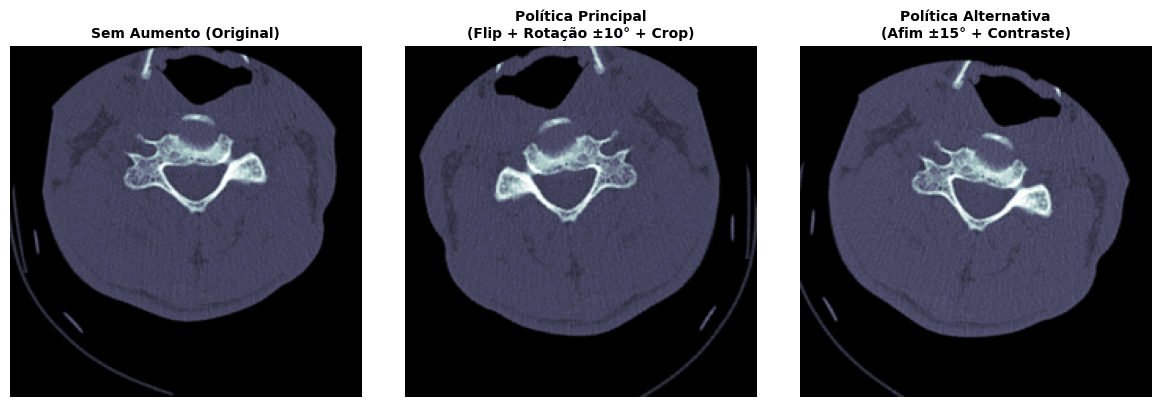

Figura salva! Paciente usado: 1.2.826.0.1.3680043.10001


In [7]:
# Pega o primeiro paciente e ordena os cortes numericamente (1.dcm, 2.dcm...)
pasta_imagens = os.path.join(caminho_base, "train_images")
paciente_exemplo = sorted(os.listdir(pasta_imagens))[0]
pasta_paciente = os.path.join(pasta_imagens, paciente_exemplo)

cortes = sorted(os.listdir(pasta_paciente), key=lambda x: int(x.split('.')[0]))
corte_central = os.path.join(pasta_paciente, cortes[len(cortes) // 2])

# Carrega a imagem original
tensor_original = carregar_corte_dicom(corte_central)

# Versões para demonstração visual na figura (forçando o espelhamento para ficar visível)
demo_principal = T.Compose([
    T.RandomHorizontalFlip(p=1.0),
    T.RandomRotation(degrees=10),
    T.RandomResizedCrop(size=(224, 224), scale=(0.90, 1.0), antialias=True)
])

demo_alternativa = T.Compose([
    T.RandomAffine(degrees=15, translate=(0.05, 0.05)),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    T.Resize((224, 224), antialias=True)
])

# Gera e salva o painel comparativo em alta resolução
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titulos = [
    "Sem Aumento (Original)",
    "Política Principal\n(Flip + Rotação ±10° + Crop)",
    "Política Alternativa\n(Afim ±15° + Contraste)"
]
imagens = [
    politica_sem_aumento(tensor_original).squeeze().numpy(),
    demo_principal(tensor_original).squeeze().numpy(),
    demo_alternativa(tensor_original).squeeze().numpy()
]

for ax, img, titulo in zip(axes, imagens, titulos):
    ax.imshow(img, cmap="bone")
    ax.set_title(titulo, fontsize=10, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.savefig("figura_data_augmentation.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Figura salva! Paciente usado: {paciente_exemplo}")